# Defensive Alignment Causal RL — Pipeline Walkthrough

Every defense in the league, every snap — runs included. Before the ball is snapped a
coordinator commits to an **alignment**: which personnel package is on the field (base,
nickel, dime) and how many defenders stand in the box. Both are chosen pre-snap and both
are charted on essentially every play, so this is an action a coordinator can actually
call and we can actually observe.

The pipeline recommends an alignment for each situation and evaluates that recommendation
from logged games alone. The central difficulty is that the offense *responds* to the
alignment — load the box and it throws; show dime and it runs — so the value of a call is
a mixture over the offense's response, not the outcome of one branch. And coordinators
choose alignments for reasons the data never recorded, which affect outcomes too.

Every estimate below is stamped with the causal graph it assumed, and every headline claim
is checked against a simulated league whose true answer is known.

## Setup

In [1]:
import os, sys, warnings, logging
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore"); logging.disable(logging.WARNING)

here = os.getcwd()
root = here if os.path.exists(os.path.join(here, "configs")) else os.path.dirname(here)
os.chdir(root); sys.path.insert(0, root)

from src.data.load import (load_pbp, load_ftn, merge_ftn, ftn_coverage,
                           generate_synthetic_alignment, true_alignment_value)
from src.data.features import (assert_ftn_coverage, build_dataset, time_aware_split,
                               PACKAGES, FRONTS)
from src.scm import graph as scm
from src.scm import identify
from src.models.behavior.propensity import fit_behavior_model
from src.models.outcome.q_model import fit_q_model, crossfit_q
from src.ope.direct_method import behavior_recovery_check
from src.ope.doubly_robust import dr_policy_value
from src.ope.ladder import ope_ladder
from src.ope.sensitivity import sensitivity_bounds, attach as attach_sensitivity
from src.policy.conservative import learn_conservative_policy
from src.evaluation import compare_to_baseline

# Chart tokens: validated categorical slots (blue, orange, aqua), ink for text,
# a recessive grid. Aqua sits below 3:1 contrast, so it only marks directly-labeled items.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda v: f"{v:+.4f}")

cfg = yaml.safe_load(open("configs/v3.yaml"))
graph = scm.graph_for(cfg); gv = graph.version_tag()
clip = cfg["ope"]["weight_clip"]
print("graph:", gv)

graph: v3.0+294ea74cccb4


## Step 1 — Data: every defense, every snap

Play-by-play from nflfastR, pre-snap charting from FTN. Personnel comes from nflfastR's
participation data; the box count from FTN. A snap enters the sample if both are charted —
which is ~99.5% of scrimmage snaps, runs and passes alike.

In [2]:
S = cfg["data"]["seasons"]
pbp = merge_ftn(load_pbp(S, cfg["data"]["cache_dir"]), load_ftn(S, cfg["data"]["cache_dir"]))
assert_ftn_coverage(pbp, cfg)
ds = build_dataset(pbp, cfg)
d = ds.df
print(f"{len(d):,} snaps · {d['defteam'].nunique()} defenses · seasons {S} · "
      f"{(d['play_type'] == 'run').mean():.1%} runs")
align = (d.groupby("action_label")
          .agg(snaps=("reward", "size"), run_rate=("play_type", lambda x: (x == "run").mean()))
          .reindex(ds.action_labels.values()))
align["share"] = align["snaps"] / align["snaps"].sum()
align[["snaps", "share", "run_rate"]].style.format({"snaps": "{:,}", "share": "{:.1%}", "run_rate": "{:.0%}"})

139,670 snaps · 32 defenses · seasons [2022, 2023, 2024, 2025] · 42.6% runs


,snaps,share,run_rate
action_label,,,
base_box_le5,"2,005",1.4%,30%
base_box6,"9,855",7.1%,54%
base_box7,"16,934",12.1%,65%
base_box_ge8,"7,369",5.3%,75%
nickel_box_le5,"14,972",10.7%,17%
nickel_box6,"54,102",38.7%,39%
nickel_box7,"16,661",11.9%,53%
nickel_box_ge8,"3,079",2.2%,71%
dime_plus_box_le5,"7,966",5.7%,12%


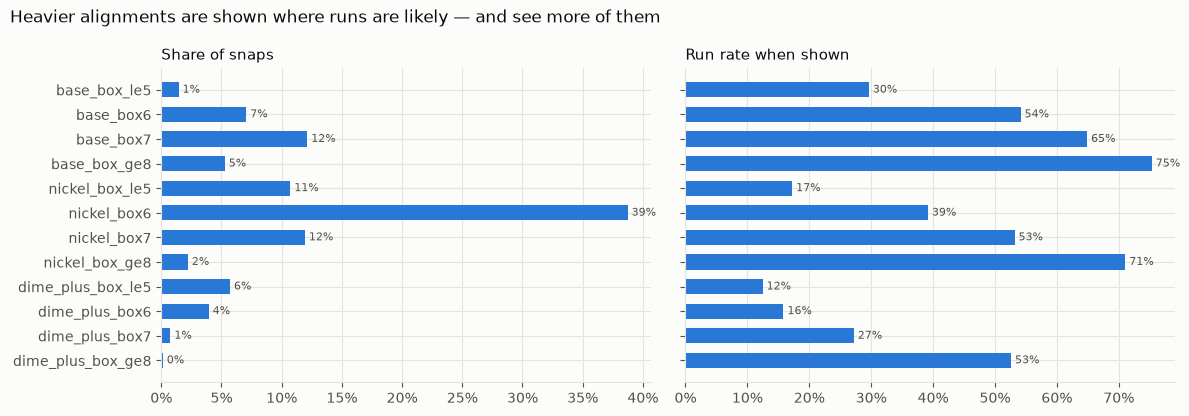

In [3]:
# Two measures on different scales -> two panels, never one chart with two axes.
order = list(ds.action_labels.values())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, col, title, fmt in [(axes[0], "share", "Share of snaps", "{:.0%}"),
                            (axes[1], "run_rate", "Run rate when shown", "{:.0%}")]:
    ax.barh(order, align.loc[order, col], color=BLUE, height=0.62)
    for y, v in enumerate(align.loc[order, col]):
        ax.text(v, y, " " + fmt.format(v), va="center", fontsize=8, color=INK2)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].invert_yaxis()
fig.suptitle("Heavier alignments are shown where runs are likely — and see more of them",
             x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.show()

The run rate climbs from ~13% against dime with a light box to ~75% against base with eight
or more in the box. That gradient is *two things at once*: coordinators show heavy looks when
they expect a run (selection), and offenses check away from a loaded box (deterrence).
Untangling them is the whole job — which is why a raw comparison of these rates would say
nothing about what an alignment *does*.

In [4]:
train, test = time_aware_split(ds, cfg["data"]["holdout_season"])
print(f"train {len(train.df):,} snaps (< {cfg['data']['holdout_season']}) · "
      f"holdout {len(test.df):,} (>= {cfg['data']['holdout_season']})")

train 105,221 snaps (< 2025) · holdout 34,449 (>= 2025)


## Step 2 — The causal graph

The treatment is the alignment. Two variables sit *downstream* of it and so must not be
adjusted for: the offense's run/pass choice (it responds to the look) and the coverage
the coordinator pairs with the alignment. The estimand is the alignment's **total** effect,
travelling through both. Team identity is a confounder — a defense's roster and scheme
drive its calls and its outcomes — and the coordinator's hidden read is the unobserved
confounder the sensitivity analysis bounds.

SCM — personnel package x front, every snap [v3.0+294ea74cccb4]
  treatment=def_alignment, outcome=epa
  adjustment set (condition on): ['game_state', 'off_formation', 'off_personnel', 'off_tendencies', 'player_proxies', 'team_identity']
    -> 27 feature columns
  mediators (do NOT condition on): ['def_coverage', 'off_playcall']
  unobserved confounders: ['coach_read'] (bounded by the sensitivity analysis)
    no dropback selection: every FTN- and personnel-charted scrimmage snap, runs included


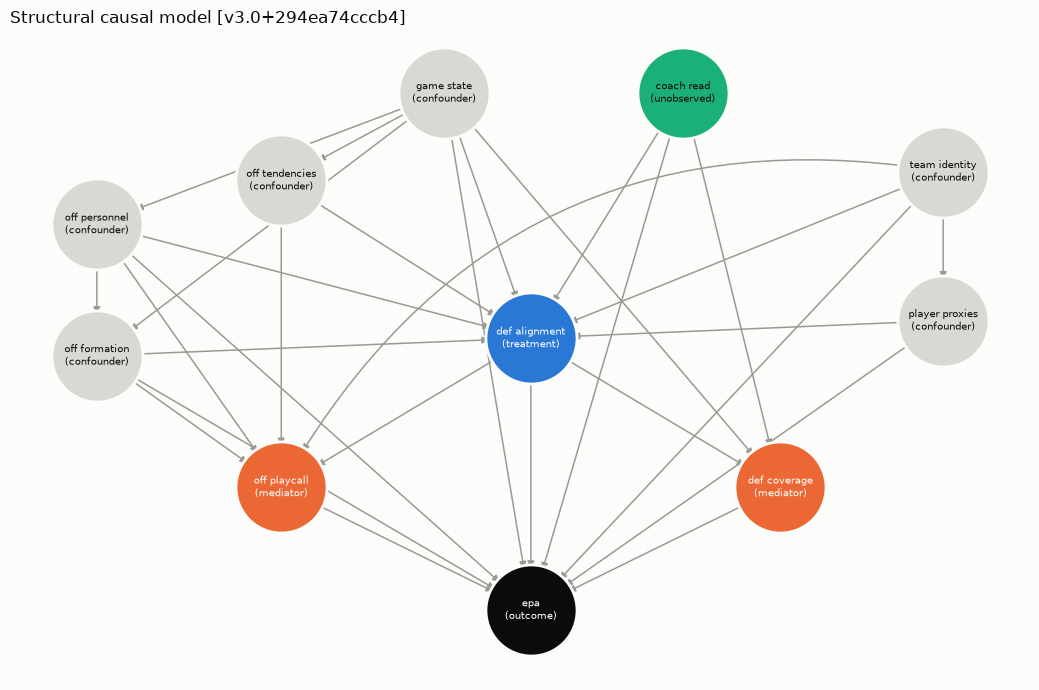

In [5]:
print(graph.describe())
# Hand layout: the hidden read sits above team identity's edges so no edge
# passes through a node it doesn't touch (that would read as a causal claim).
pos = {"game_state": (-0.8, 3.4), "coach_read": (1.4, 3.4), "team_identity": (3.8, 2.5),
       "player_proxies": (3.8, 0.8), "off_tendencies": (-2.3, 2.4), "off_personnel": (-4.0, 1.9),
       "off_formation": (-4.0, 0.4), "def_alignment": (0, 0.6), "off_playcall": (-2.3, -1.1),
       "def_coverage": (2.3, -1.1), "epa": (0, -2.5)}
role = {graph.treatment: (BLUE, "white", "treatment"), graph.outcome: (INK, "white", "outcome")}
role |= {m: (ORANGE, "white", "mediator") for m in graph.mediators}
role |= {u: (AQUA, INK, "unobserved") for u in graph.unobserved}
fig, ax = plt.subplots(figsize=(10.5, 7)); ax.grid(False); ax.axis("off")
for s, t in graph.edges:
    (x0, y0), (x1, y1) = pos[s], pos[t]
    # Curve the one edge whose straight line would cross the treatment node.
    rad = 0.35 if (s, t) == ("team_identity", "off_playcall") else 0.0
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), zorder=1,
                arrowprops=dict(arrowstyle="-|>", lw=1.1, color="#9a9994", shrinkA=30, shrinkB=30,
                                connectionstyle=f"arc3,rad={rad}"))
for n, (x, y) in pos.items():
    fc, tc, tag = role.get(n, ("#d9d8d2", INK, "confounder"))
    ax.scatter([x], [y], s=4300, c=fc, zorder=3, edgecolors=SURFACE, linewidths=2)
    ax.text(x, y, f"{n.replace('_', ' ')}\n({tag})", ha="center", va="center",
            fontsize=7.5, color=tc, zorder=4)
ax.set_xlim(-4.8, 4.6); ax.set_ylim(-3.3, 4.1)
ax.set_title(f"Structural causal model [{gv}]", loc="left", fontsize=12)
plt.tight_layout(); plt.show()

DoWhy: backdoor-identified via 27 adjustment variables


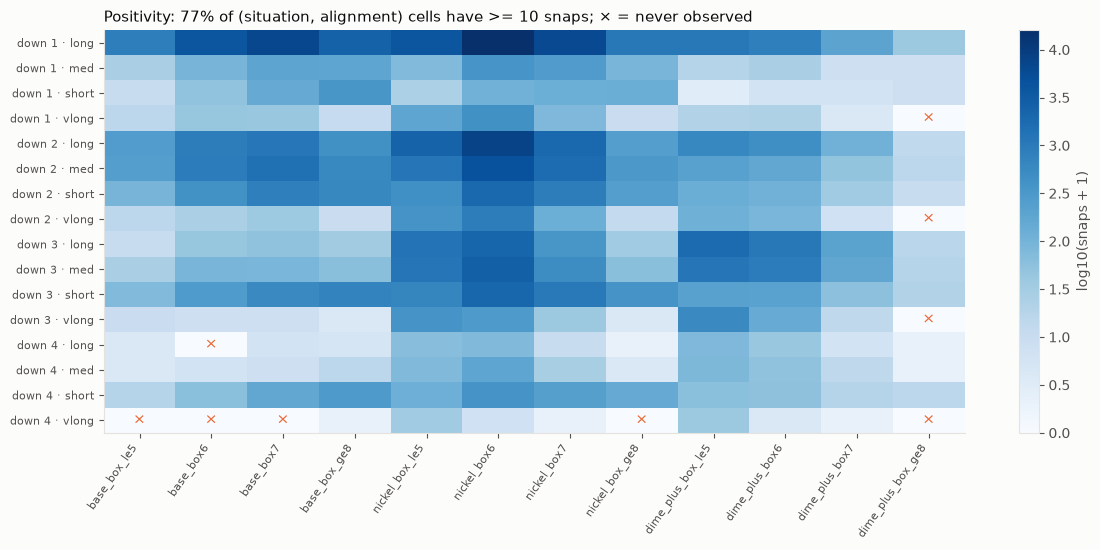

In [6]:
est = identify.identify_estimand(identify.build_causal_model(train, graph=graph))
print(f"DoWhy: backdoor-identified via {len(est.get_backdoor_variables())} adjustment variables")
pos_ = identify.check_positivity(train, cfg["positivity"]["min_count"])
cov = pos_["coverage"].set_index(pos_["strata_cols"])[list(range(ds.n_actions))]
cov.columns = order
fig, ax = plt.subplots(figsize=(12, 5.6)); ax.grid(False)
im = ax.imshow(np.log10(cov.values + 1), cmap="Blues", aspect="auto")
ax.set_xticks(range(len(order)), order, rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(len(cov)), [f"down {a} · {b}" for a, b in cov.index], fontsize=8)
for (i, j), v in np.ndenumerate(cov.values):
    if v == 0: ax.text(j, i, "×", ha="center", va="center", color=ORANGE, fontsize=11)
plt.colorbar(im, ax=ax, label="log10(snaps + 1)")
ax.set_title(f"Positivity: {pos_['pct_cells_supported']:.0%} of (situation, alignment) cells "
             f"have >= {pos_['min_count']} snaps; × = never observed", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

Pooling every defense is what makes positivity workable: most (situation, alignment) cells are
populated. The empty ones are mostly football — nobody shows dime with eight in the box on
third-and-long — and the policy is forbidden from recommending there.

## Step 3 — What coordinators actually call: π_b(A | S)

A calibrated gradient-boosted classifier over the twelve alignments. Its probabilities become
importance weights, so they are judged as probabilities: calibration is reported as a triple
(top-class confidence, every-class, and a proper scoring rule), and all diagnostics are
cross-fitted rather than in-sample.

In [7]:
beh, diag = fit_behavior_model(train, cfg)
print(f"accuracy {diag['oof_accuracy']:.3f} (majority {diag['majority_baseline']:.3f}) · "
      f"log loss {diag['oof_log_loss']:.3f} · ESS ratio {diag['ess_ratio']:.3f}")
print(f"confidence ECE {diag['confidence_ece']:.3f} · classwise ECE {diag['classwise_ece']:.3f} · "
      f"Brier {diag['brier']:.3f}")

accuracy 0.499 (majority 0.381) · log loss 1.378 · ESS ratio 0.212
confidence ECE 0.045 · classwise ECE 0.012 · Brier 0.645


## Step 4 — What would have happened: Q(S, A)

One gradient-boosted regressor over the pre-snap state *and* the alignment's two components
— package and front — rather than twelve separate models. Separate per-alignment models
estimate each cell with independent noise, inflating the spread between alignments; a policy
that maximizes Q then chases whichever cell is most overestimated. A pooled model lets a
rarely-shown alignment borrow from every alignment that shares its package or its front.

The question worth asking of any outcome model is not its fit but whether its *action effects*
behave like causes. Here are the two components' effects, by situation:

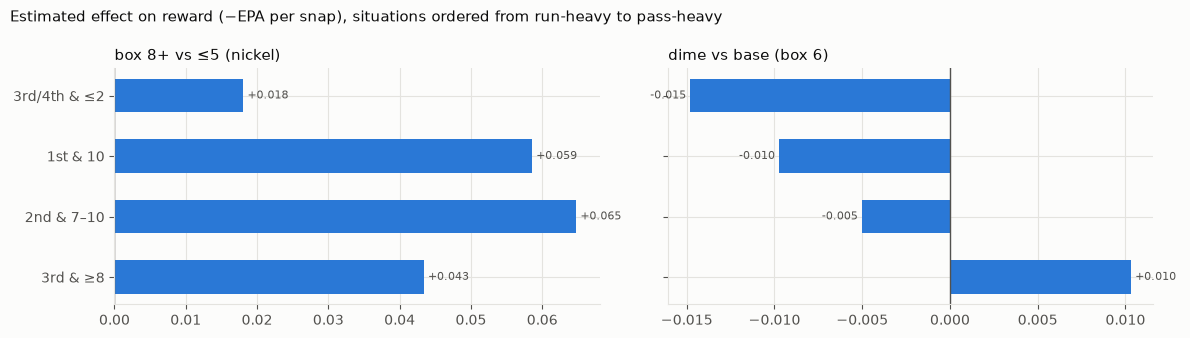

,run rate,box 8+ vs ≤5 (nickel),dime vs base (box 6)
3rd/4th & ≤2,65%,+0.0181,-0.0148
1st & 10,53%,+0.0586,-0.0097
2nd & 7–10,33%,+0.0648,-0.0050
3rd & ≥8,14%,+0.0434,+0.0103


In [8]:
q = fit_q_model(train, cfg)
dt = test.df; Qt = q.predict_all_actions(dt)
lab = {v: k for k, v in ds.action_labels.items()}
sit = {"3rd/4th & ≤2": (dt.down >= 3) & (dt.ydstogo <= 2),
       "1st & 10": (dt.down == 1) & (dt.ydstogo == 10),
       "2nd & 7–10": (dt.down == 2) & dt.ydstogo.between(7, 10),
       "3rd & ≥8": (dt.down == 3) & (dt.ydstogo >= 8)}
eff = pd.DataFrame({
    "run rate": [(dt.loc[m, "play_type"] == "run").mean() for m in sit.values()],
    "box 8+ vs ≤5 (nickel)": [(Qt[m, lab["nickel_box_ge8"]] - Qt[m, lab["nickel_box_le5"]]).mean() for m in sit.values()],
    "dime vs base (box 6)": [(Qt[m, lab["dime_plus_box6"]] - Qt[m, lab["base_box6"]]).mean() for m in sit.values()],
}, index=list(sit))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, col in zip(axes, eff.columns[1:]):
    ax.barh(eff.index, eff[col], color=BLUE, height=0.55); ax.axvline(0, color=INK2, lw=1)
    for y, v in enumerate(eff[col]):
        ax.text(v, y, f" {v:+.3f} ", va="center", ha="left" if v >= 0 else "right", fontsize=8, color=INK2)
    ax.set_title(col, loc="left", fontsize=11, color=INK)
axes[0].invert_yaxis()
fig.suptitle("Estimated effect on reward (−EPA per snap), situations ordered from run-heavy to pass-heavy",
             x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()
eff.style.format({"run rate": "{:.0%}", "box 8+ vs ≤5 (nickel)": "{:+.4f}", "dime vs base (box 6)": "{:+.4f}"})

**Read these two panels differently.** The package effect behaves like a cause: base personnel
is better where runs are likely, dime is better on third-and-long, and the sign flips in
between. The box effect does not: it is positive everywhere and *smallest* exactly where runs
are most likely — backwards from how stacking the box against the run should work.

The likeliest explanation is that on passing downs a loaded box is mostly a **pressure look**,
so its estimated effect is travelling through the pressure call — which is part of the
alignment's total effect by construction here, but is not the run-fit mechanism the box is
usually credited with — possibly mixed with the unrecorded read. Separating the run-fit channel
from the pressure channel needs the coverage-and-pressure call modeled explicitly given the
alignment. Until then, the box effect is a total effect whose mechanism is unresolved, and it
should not be read as "stack the box."

## Step 5 — Scoring the behavior policy first

Before any off-policy estimate is believed, OPE has to reproduce the coordinators' own mean
reward. The outcome model is cross-fitted so the check is not scoring its own training rows.

In [9]:
mu = crossfit_q(train, cfg)
rec = behavior_recovery_check(train, q, beh, q_all=mu, weight_clip=clip, graph_version=gv)
print(f"empirical {rec['empirical_reward']:+.4f} · DM {rec['dm_under_pi_b']:+.4f} · "
      f"DR {rec['dr_under_pi_b']:+.4f} · gap {rec['recovery_gap']:.4f} -> "
      f"{'PASS' if rec['passes'] else 'FAIL'}")

empirical +0.0077 · DM +0.0086 · DR +0.0083 · gap 0.0006 -> PASS


## Step 6 — The recommendation, on a season it never saw

The policy picks the alignment with the best pessimism-penalized Q among alignments with real
support in that situation. It is then scored on the held-out season four ways: DM trusts the
outcome model, IPW and SNIPW trust the propensities, DR needs only one of them to be right.

In [10]:
policy = learn_conservative_policy(train, q, beh, cfg)
out = policy.act(dt)
a_te, r_te, pib = dt["action"].to_numpy(), dt["reward"].to_numpy(), beh.propensity(dt)
ladder = pd.concat([
    ope_ladder(Qt, pib, pib, a_te, r_te, clip, policy_name="behavior", graph_version=gv),
    ope_ladder(Qt, pib, out["policy_probs"], a_te, r_te, clip, policy_name="conservative", graph_version=gv),
], ignore_index=True)
v_b = dr_policy_value(Qt, pib, pib, a_te, r_te, clip, policy_name="behavior", graph_version=gv)
v_p = dr_policy_value(Qt, pib, out["policy_probs"], a_te, r_te, clip, policy_name="conservative", graph_version=gv)
idx = np.arange(len(a_te))
print(f"agrees with the coordinator on {np.mean(out['chosen'] == a_te):.1%} of snaps · "
      f"mean π_b of its calls {pib[idx, out['chosen']].mean():.3f} (coordinators' own: {pib[idx, a_te].mean():.3f})")
ladder[["policy", "estimator", "value", "se", "support_share", "ess_ratio"]]

agrees with the coordinator on 40.7% of snaps · mean π_b of its calls 0.403 (coordinators' own: 0.321)


,policy,estimator,value,se,support_share,ess_ratio
0,behavior,DM,+0.0068,+0.0008,+1.0000,+1.0000
1,behavior,IPW,-0.0052,+0.0074,+1.0000,+1.0000
2,behavior,SNIPW,-0.0052,+0.0074,+1.0000,+1.0000
3,behavior,DR-SN,-0.0034,+0.0074,+1.0000,+1.0000
4,conservative,DM,+0.0171,+0.0008,+0.4067,+0.3221
5,conservative,IPW,-0.0052,+0.0130,+0.4067,+0.3221
6,conservative,SNIPW,-0.0053,+0.0135,+0.4067,+0.3221
7,conservative,DR-SN,-0.0020,+0.0135,+0.4067,+0.3221


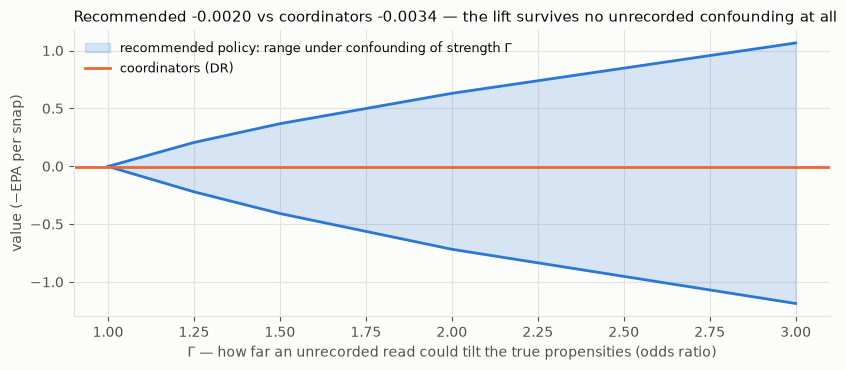

,policy,estimator,value,ci_lo,ci_hi,graph_version,robust_to_gamma
0,behavior,DR-SN,-0.0034,-0.0180,+0.0112,v3.0+294ea74cccb4,NaN
1,conservative,DR-SN,-0.0020,-0.0284,+0.0244,v3.0+294ea74cccb4,+1.0000


In [11]:
sens = sensitivity_bounds(Qt, pib, out["policy_probs"], a_te, r_te, [1.0, 1.25, 1.5, 2.0, 3.0],
                          clip, compare_value=v_b.value, policy_name="conservative")
attach_sensitivity(v_p, sens)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.fill_between(sens["gamma"], sens["v_lower"], sens["v_upper"], color=BLUE, alpha=0.18,
                label="recommended policy: range under confounding of strength Γ")
ax.plot(sens["gamma"], sens["v_lower"], color=BLUE, lw=2); ax.plot(sens["gamma"], sens["v_upper"], color=BLUE, lw=2)
ax.axhline(v_b.value, color=ORANGE, lw=2, label="coordinators (DR)")
ax.set_xlabel("Γ — how far an unrecorded read could tilt the true propensities (odds ratio)")
ax.set_ylabel("value (−EPA per snap)"); ax.legend(frameon=False, loc="upper left", fontsize=9)
g = v_p.robust_to_gamma
verdict = ("the lift survives no unrecorded confounding at all" if not g or g <= 1.0
           else f"the lift survives confounding up to Γ = {g}")
ax.set_title(f"Recommended {v_p.value:+.4f} vs coordinators {v_b.value:+.4f} — {verdict}",
             loc="left", fontsize=11)
plt.tight_layout(); plt.show()
pd.DataFrame([v_b.to_record(), v_p.to_record()])[["policy", "estimator", "value", "ci_lo", "ci_hi", "graph_version", "robust_to_gamma"]]

The recommended policy and the coordinators are **statistically indistinguishable** on the
held-out season, and the band says even a mild unrecorded read could swamp the difference.
All four rungs of the ladder agree to within their error — no nuisance model is misbehaving —
so this is a real null, not a broken estimator. It is the result an equilibrium would predict:
across a league of professional coordinators, any alignment shown often enough to be estimated
is shown roughly as often as it earns.

## Step 7 — The regression gate

The candidate is scored against the behavior-constrained greedy baseline on the same held-out
snaps with the same models, so the difference is paired and the shared noise cancels. The
gate blocks only on a proven deterioration past the margin.

In [12]:
cmp = compare_to_baseline(test, q, beh, cfg)
print(cmp.report())

  V_DR(greedy_baseline       ) = -0.0336
  V_DR(conservative_candidate) = -0.0020
  paired difference     = +0.0316  95% CI [-0.0169, +0.0801]  (n=34449)
  non-inferiority margin= 0.0200
  verdict: NO CHANGE DETECTED  ->  gate passes


The greedy baseline — pure argmax Q over supported alignments — scores *below* the coordinators:
maximizing a noisy Q selects its most overestimated entries. The pessimism penalty is what
pulls the recommendation back to alignments the data can vouch for.

## Recommendations in the situations that matter

In [13]:
rows = []
for name, where in [("3rd/4th & short", (dt.down >= 3) & (dt.ydstogo <= 2)),
                    ("goal-to-go inside the 5", dt.yardline_100 <= 5),
                    ("1st & 10", (dt.down == 1) & (dt.ydstogo == 10)),
                    ("3rd & long", (dt.down == 3) & (dt.ydstogo >= 8))]:
    pool = dt[where]
    rec_ = policy.act(pool)["chosen"]
    top = pd.Series(rec_).map(ds.action_labels).value_counts(normalize=True)
    dc = pool["action_label"].value_counts(normalize=True)
    rows.append({"situation": name, "snaps": len(pool),
                 "most-recommended": f"{top.index[0]} ({top.iloc[0]:.0%})",
                 "coordinators' most-common": f"{dc.index[0]} ({dc.iloc[0]:.0%})"})
pd.DataFrame(rows)

,situation,snaps,most-recommended,coordinators' most-common
0,3rd/4th & short,2013,nickel_box6 (36%),nickel_box6 (33%)
1,goal-to-go inside the 5,1360,base_box_ge8 (51%),base_box_ge8 (27%)
2,1st & 10,13464,nickel_box6 (40%),nickel_box6 (38%)
3,3rd & long,2792,nickel_box6 (50%),nickel_box6 (35%)


## Validation aside — a league whose answer is known

The same pipeline, run on a simulated league built with deterrence: a heavier alignment is good
against the run, bad against the pass, *and* makes the offense less likely to run at all. A
hidden read drives both the coordinator's call and the outcome. Because the true value of any
policy is computable, three claims become checkable against truth rather than against another
estimate.

In [14]:
scfg = {**cfg, "data": {**cfg["data"]}}
syn = build_dataset(generate_synthetic_alignment(9000, seed=11, seasons=S), scfg)
s_tr, s_te = time_aware_split(syn, cfg["data"]["holdout_season"])
s_beh, _ = fit_behavior_model(s_tr, scfg); s_q = fit_q_model(s_tr, scfg)
s_out = learn_conservative_policy(s_tr, s_q, s_beh, scfg).act(s_te.df)
sd = s_te.df; sa = sd["action"].to_numpy(); sr = sd["reward"].to_numpy()
sQ = s_q.predict_all_actions(sd); spib = s_beh.propensity(sd)
dr_b = dr_policy_value(sQ, spib, spib, sa, sr, clip)
band = sensitivity_bounds(sQ, spib, s_out["policy_probs"], sa, sr, [1.0, 3.0], clip).set_index("gamma")
t_b, t_p = true_alignment_value(sd, sa), true_alignment_value(sd, s_out["chosen"])
pd.DataFrame({
    "claim": ["recommended policy beats the coordinator in truth",
              "DR recovers the coordinator's true value",
              "the Γ=3 band contains the recommended policy's true value"],
    "evidence": [f"true {t_p:+.4f} vs {t_b:+.4f}",
                 f"DR {dr_b.value:+.4f} ± {1.96*dr_b.se:.4f} vs true {t_b:+.4f}",
                 f"[{band.loc[3.0,'v_lower']:+.4f}, {band.loc[3.0,'v_upper']:+.4f}] ∋ {t_p:+.4f}"],
    "holds": [t_p > t_b, abs(dr_b.value - t_b) <= 3 * dr_b.se,
              band.loc[3.0, "v_lower"] <= t_p <= band.loc[3.0, "v_upper"]],
})

,claim,evidence,holds
0,recommended policy beats the coordinator in truth,true +0.0352 vs +0.0179,True
1,DR recovers the coordinator's true value,DR +0.0192 ± 0.0270 vs true +0.0179,True
2,the Γ=3 band contains the recommended policy's...,"[-0.5773, +0.5879] ∋ +0.0352",True


All three are also pinned as regression tests. One caution the simulation makes concrete: on a
holdout this small, DR's error on a *new* policy's value is about as large as the true gain,
so a single point estimate there can land on either side of the truth. The real holdout is
roughly sixteen times larger, which is what makes its null result informative rather than
merely underpowered.

## Summary

- **Every snap is in.** Runs included, all defenses pooled: short yardage and goal line are
  learnable, and the alignment's deterrence effect is inside the estimand rather than
  selected away.
- **The alignment is a real, callable action** — chosen before the snap, observed on ~100% of
  plays.
- **The recommended policy does no harm and no measurable good.** It matches the coordinators
  on the held-out season within error, robust to nothing stronger than Γ = 1. Pure argmax-Q
  does worse; the pessimism penalty and the support floor are what keep it honest.
- **The package effect looks causal; the box effect does not yet.** Its estimated effect is
  largest on passing downs, which points at the pressure call rather than run fits.

Next: model the coverage-and-pressure call given the alignment, which both separates the box's
two channels and completes the factored recommendation; then test whether the effects that
survive transfer across teams and seasons.